# ĐÁP ÁN ĐỀ THI CUỐI KỲ - PHÂN TÍCH DỮ LIỆU BAYESIAN
## Môn: Phân tích dữ liệu Bayesian.
## Ngày: 30/05/2026
## Lớp: DHKHDL18A. Thời gian: 75 phút
## Điểm: ..... / 10

---

**Lưu ý:** Đây là bản lời giải tham khảo cho đề `CuoiKy_Bayesian_2026_Final.ipynb`.

---

### Câu 1. (2.0 điểm) Normal-Normal Conjugate

**Đề bài:**
Giả sử ta có prior cho tham số $\theta$:

$$\theta \sim \mathcal{N}(\mu_0 = 5, \sigma_0^2 = 4)$$

Giả sử ta thu thập được $n = 10$ quan sát độc lập từ phân phối chuẩn:

$$Y_i \mid \theta \sim \mathcal{N}(\theta, \sigma^2 = 1)$$

với các giá trị quan sát:

$$\bar{y} = 6.3, \quad \sum_{i=1}^{10} y_i = 63$$

a) Xác định phân phối hậu nghiệm (posterior) của $\theta$.

b) Tính kỳ vọng và phương sai của posterior.

c) Tính ước lượng MAP và so sánh với posterior mean.

d) Vẽ đồ thị so sánh prior, likelihood, và posterior trên cùng một hệ trục tọa độ.

**Giải:**

**a) Posterior Distribution**

Đây là cặp liên hợp **Normal-Normal**: prior $\mathcal{N}(\mu_0, \sigma_0^2)$ + likelihood Normal với known variance $\sigma^2$ → posterior cũng Normal.

Công thức cập nhật:

$$\frac{1}{\sigma_n^2} = \frac{1}{\sigma_0^2} + \frac{n}{\sigma^2}$$

$$\frac{\mu_n}{\sigma_n^2} = \frac{\mu_0}{\sigma_0^2} + \frac{\sum y_i}{\sigma^2}$$

Với $\mu_0 = 5$, $\sigma_0^2 = 4$ (nên $\sigma_0 = 2$), $\sigma^2 = 1$, $n = 10$, $\sum y_i = 63$:

$$\frac{1}{\sigma_n^2} = \frac{1}{4} + \frac{10}{1} = 0.25 + 10 = 10.25$$

$$\sigma_n^2 = \frac{1}{10.25} = \frac{4}{41} \approx 0.09756, \quad \sigma_n \approx 0.3123$$

$$\frac{\mu_n}{\sigma_n^2} = \frac{5}{4} + \frac{63}{1} = 1.25 + 63 = 64.25$$

$$\mu_n = 64.25 \times \sigma_n^2 = 64.25 \times \frac{4}{41} = \frac{257}{41} \approx 6.2683$$

**b) Kỳ vọng và Phương sai của Posterior**

$$E[\theta \mid D] = \mu_n = 6.2683$$

$$\text{Var}(\theta \mid D) = \sigma_n^2 = 0.09756$$

**c) MAP Estimation**

Với phân phối Normal đối xứng, **MAP = Mean = Median**:

$$\text{MAP} = \mu_n = 6.2683$$

**Nhận xét về Shrinkage (co rút về prior):**

Posterior mean $\mu_n$ là **trung bình có trọng số** giữa prior mean và sample mean, với trọng số tỷ lệ thuận với **precision** (nghịch đảo phương sai):

$$\mu_n = \frac{\frac{1}{\sigma_0^2}}{\frac{1}{\sigma_0^2} + \frac{n}{\sigma^2}} \cdot \mu_0 + \frac{\frac{n}{\sigma^2}}{\frac{1}{\sigma_0^2} + \frac{n}{\sigma^2}} \cdot \bar{y}$$

$$= \frac{0.25}{10.25} \times 5 + \frac{10}{10.25} \times 6.3 \approx 0.0244 \times 5 + 0.9756 \times 6.3 = 6.2683$$

**Ý nghĩa:**
- Với $n=10$ quan sát, dữ liệu chiếm **97.6%** trọng số → posterior gần với sample mean.
- Prior chỉ đóng góp **2.4%** → prior yếu so với dữ liệu.
- Phương sai posterior $\sigma_n^2 = 0.098 \ll \sigma_0^2 = 4$: dữ liệu đã giảm bất định rất mạnh (từ $\sigma_0=2$ xuống $\sigma_n \approx 0.31$).
- Nếu $n \to \infty$, posterior mean $\to \bar{y}$ (dữ liệu áp đảo prior).
- Nếu $n = 0$, posterior = prior (chưa có dữ liệu).

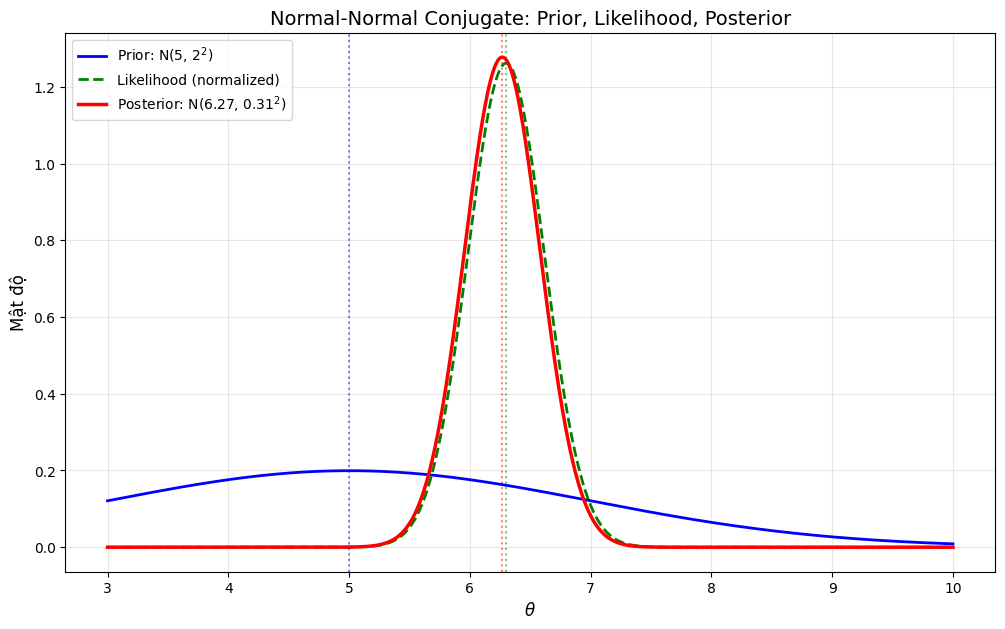

Prior: μ₀ = 5, σ₀² = 4
Posterior: μₙ = 6.2683, σₙ² = 0.0976
MAP = Mean = 6.2683


In [1]:
# Vẽ đồ thị so sánh prior, likelihood, posterior
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

theta = np.linspace(3, 10, 1000)

# Prior: N(5, 4)
prior = stats.norm.pdf(theta, loc=5, scale=2)

# Likelihood (proportional): N(6.3, 1/10) for sample mean
likelihood = stats.norm.pdf(theta, loc=6.3, scale=1/np.sqrt(10))

# Posterior: N(6.2683, 0.09756)
posterior = stats.norm.pdf(theta, loc=257/41, scale=np.sqrt(4/41))

plt.figure(figsize=(12, 7))
plt.plot(theta, prior, 'b-', linewidth=2, label=r'Prior: N(5, $2^2$)')
plt.plot(theta, likelihood, 'g--', linewidth=2, label='Likelihood (normalized)')
plt.plot(theta, posterior, 'r-', linewidth=2.5, label=r'Posterior: N(6.27, $0.31^2$)')

plt.axvline(x=5, color='blue', linestyle=':', alpha=0.5)
plt.axvline(x=6.3, color='green', linestyle=':', alpha=0.5)
plt.axvline(x=257/41, color='red', linestyle=':', alpha=0.5)

plt.xlabel(r'$\theta$', fontsize=12)
plt.ylabel('Mật độ', fontsize=12)
plt.title('Normal-Normal Conjugate: Prior, Likelihood, Posterior', fontsize=14)
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.show()

print(f"Prior: μ₀ = 5, σ₀² = 4")
print(f"Posterior: μₙ = {257/41:.4f}, σₙ² = {4/41:.4f}")
print(f"MAP = Mean = {257/41:.4f}")

---

### Câu 2. (2.0 điểm) Custom Prior + MAP + Loss Functions

**Đề bài:**
Giả sử ta có phân phối tiên nghiệm (prior) cho tham số $x$:

$$f_X(x) = 6x(1-x), \quad 0 \leq x \leq 1.$$

Giả sử likelihood của một quan sát $Y$ là phân phối đều trên $[0, x]$:

$$f_{Y|X}(y|x) = \frac{1}{x}, \quad 0 \leq y \leq x.$$

Quan sát được $y = 0.4$.

a) Xác định phân phối hậu nghiệm (posterior) $p(x \mid y = 0.4)$ và vẽ đồ thị.

b) Tính ước lượng điểm tốt nhất với:
   - Loss function bình phương (squared loss) → Posterior Mean
   - Loss function 0-1 (all-or-nothing) → Posterior Mode (MAP)


**Phân tích Prior và Likelihood trước khi áp dụng Bayes:**

**Prior $f_X(x) = 6x(1-x)$** là phân phối **Beta(2, 2)** trên $[0,1]$.

Kiểm tra tính hợp lệ (tổng xác suất = 1):

$$\int_0^1 6x(1-x)\,dx = 6\left[\frac{x^2}{2} - \frac{x^3}{3}\right]_0^1 = 6\left(\frac{1}{2} - \frac{1}{3}\right) = 6 \times \frac{1}{6} = 1 \checkmark$$

Đỉnh của prior tại $x^* = \arg\max 6x(1-x)$: đặt đạo hàm bằng 0 $\Rightarrow 6(1-2x)=0 \Rightarrow x^*=0.5$. Prior tin rằng $x$ có khả năng cao nằm gần $0.5$, giảm về $0$ ở hai đầu.

**Likelihood $f_{Y|X}(y|x) = \frac{1}{x}$, $0 \leq y \leq x$** là phân phối **Đều (Uniform)** trên $[0, x]$.

Kiểm tra: $\int_0^x \frac{1}{x}\,dy = \frac{1}{x} \cdot x = 1 \checkmark$

Ý nghĩa: nếu biết $x$, quan sát $Y$ có thể nhận bất kỳ giá trị nào trong $[0, x]$ với xác suất đều nhau. Giá trị $x$ càng lớn thì mỗi điểm trong $[0,x]$ càng ít có khả năng xảy ra (mật độ $1/x$ càng nhỏ).

**Ràng buộc miền sau khi quan sát $y = 0.4$:**

Likelihood $f_{Y|X}(y|x) = \frac{1}{x}$ chỉ xác định khi $y \leq x$. Với $y=0.4$, mọi $x < 0.4$ đều có likelihood $= 0$ (không thể quan sát $y=0.4$ nếu $x < 0.4$). Do đó posterior chỉ có support trên $[0.4, 1]$.

**Giải:**

**a) Tìm Posterior**

Theo Bayes theorem:

$$p(x \mid y) \propto p(y \mid x) \cdot p(x)$$

Với $y = 0.4$:

$$p(x \mid y=0.4) \propto \frac{1}{x} \cdot 6x(1-x) = 6(1-x), \quad x \in [0.4, 1]$$

Vì $0 \leq y \leq x$, và $y = 0.4$, nên $x$ phải $\geq 0.4$.

Chuẩn hóa để có phân phối hợp lệ:

$$\int_{0.4}^{1} 6(1-x) \, dx = 6\left[x - \frac{x^2}{2}\right]_{0.4}^{1} = 6\left[(1 - 0.5) - (0.4 - 0.08)\right] = 6 \times 0.18 = 1.08$$

Vậy:

$$p(x \mid y=0.4) = \frac{6(1-x)}{1.08} = \frac{50}{9}(1-x), \quad 0.4 \leq x \leq 1$$

**Nhận xét:** Posterior là **hàm giảm** theo $x$, không giống prior Beta(2,2) dạng parabol đối xứng. Dữ liệu $y=0.4$ kéo trọng số về phía các giá trị $x$ nhỏ.


**Lưu ý về hằng số chuẩn hóa:**

Hằng số $C = 1.08$ được tính bằng cách tích phân unnormalized posterior trên toàn miền hợp lệ:

$$C = \int_{0.4}^{1} 6(1-x)\,dx = 6\left[x - \frac{x^2}{2}\right]_{0.4}^{1} = 6\left[(1 - 0.5) - (0.4 - 0.08)\right] = 6 \times 0.18 = 1.08$$

Điều này đảm bảo $\int_{0.4}^{1} p(x \mid y)\,dx = 1$. Miền tích phân bắt đầu từ $x = 0.4$ (không phải $0$) vì likelihood $f_{Y|X}(y|x) = \frac{1}{x}$ chỉ xác định khi $y \leq x$, tức $x \geq y = 0.4$.

**b) Tính ước lượng với các loss functions**

**Squared Loss → Posterior Mean:**

$$E[x \mid y] = \int_{0.4}^{1} x \cdot \frac{6(1-x)}{1.08} \, dx = \frac{6}{1.08} \int_{0.4}^{1} (x - x^2) \, dx$$

$$= \frac{6}{1.08} \left[\frac{x^2}{2} - \frac{x^3}{3}\right]_{0.4}^{1} = \frac{6}{1.08} \times 0.108 = 0.6$$

**Kiểm tra:** $E[x] = \frac{6}{1.08}[(0.5 - 0.3333) - (0.08 - 0.0213)] = \frac{6}{1.08}[0.1667 - 0.0587] = \frac{6}{1.08} \times 0.108 = 0.6$ ✓

**0-1 Loss → Posterior Mode (MAP):**

$p(x \mid y) = \frac{6(1-x)}{1.08}$ là hàm giảm theo $x$, nên mode tại **điểm nhỏ nhất** của miền $[0.4, 1]$:

$$\text{MAP} = 0.4$$

**Tóm tắt:**
- Posterior Mean (squared loss): **0.6**
- MAP (0-1 loss): **0.4**


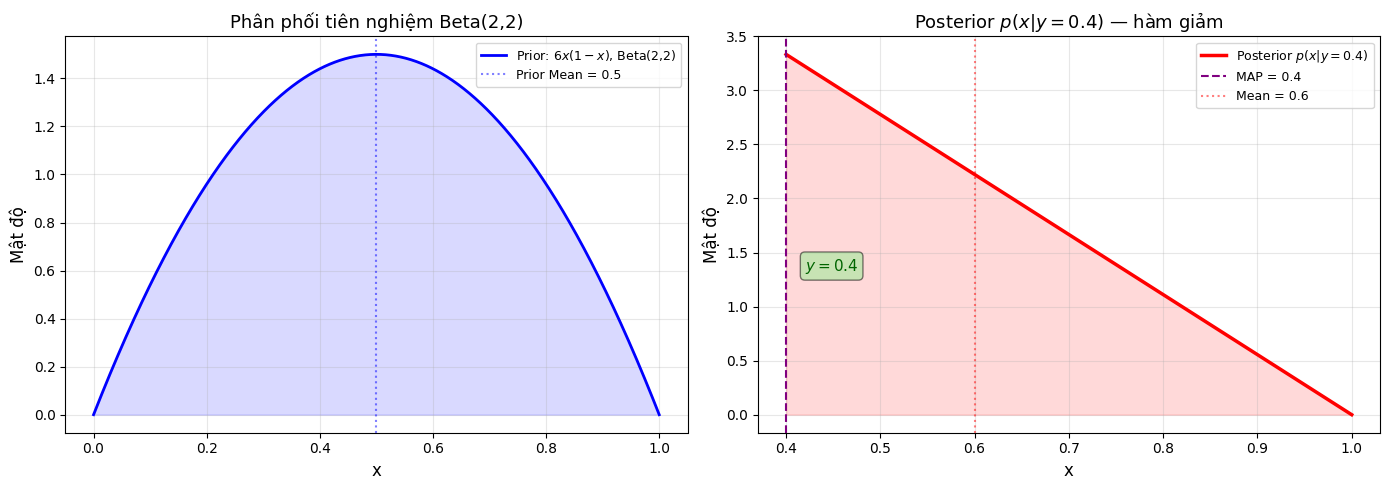

Prior: Beta(2,2), Mean = 0.5, Mode = 0.5
Posterior domain: [0.4, 1]
MAP (0-1 loss) = 0.4 (tại biên trái)
Mean (squared loss) = 0.6
Nhận xét: posterior giảm → MAP ≠ Mean


In [2]:
# Vẽ đồ thị prior và posterior
import numpy as np
import matplotlib.pyplot as plt

# Prior: Beta(2,2) = 6x(1-x)
x_grid_prior = np.linspace(0, 1, 1000)
prior = 6 * x_grid_prior * (1 - x_grid_prior)

# Posterior: defined on [0.4, 1]
x_grid_post = np.linspace(0.4, 1, 600)
posterior = 6 * (1 - x_grid_post) / 1.08

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Prior Beta(2,2)
ax = axes[0]
ax.plot(x_grid_prior, prior, 'b-', linewidth=2, label=r'Prior: $6x(1-x)$, Beta(2,2)')
ax.fill_between(x_grid_prior, prior, alpha=0.15, color='blue')
ax.axvline(x=0.5, color='blue', linestyle=':', alpha=0.5, label='Prior Mean = 0.5')
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('Mật độ', fontsize=12)
ax.set_title('Phân phối tiên nghiệm Beta(2,2)', fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# Right: Posterior with prior overlay
ax = axes[1]
ax.plot(x_grid_post, posterior, 'r-', linewidth=2.5, label=r'Posterior $p(x|y=0.4)$')
ax.fill_between(x_grid_post, posterior, alpha=0.15, color='red')
ax.axvline(x=0.4, color='purple', linestyle='--', linewidth=1.5, label='MAP = 0.4')
ax.axvline(x=0.6, color='red', linestyle=':', alpha=0.5, label='Mean = 0.6')
ax.text(0.42, max(posterior)*0.4, r'$y=0.4$', fontsize=11, color='darkgreen',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='lightgreen', alpha=0.5))
ax.set_xlabel('x', fontsize=12)
ax.set_ylabel('Mật độ', fontsize=12)
ax.set_title(r'Posterior $p(x|y=0.4)$ — hàm giảm', fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Prior: Beta(2,2), Mean = 0.5, Mode = 0.5")
print(f"Posterior domain: [0.4, 1]")
print(f"MAP (0-1 loss) = 0.4 (tại biên trái)")
print(f"Mean (squared loss) = 0.6")
print(f"Nhận xét: posterior giảm → MAP ≠ Mean")


---

### Câu 3. (3.0 điểm) Mixture Prior


**Đề bài:**
Một nhà nghiên cứu muốn ước lượng điểm trung bình $\mu$ của một bài kiểm tra. Trước khi có dữ liệu, dựa trên hai nguồn thông tin khác nhau, nhà nghiên cứu xây dựng mixture prior:

$$p(\mu) = 0.5 \cdot \mathcal{N}(\mu \mid 3, 1) + 0.5 \cdot \mathcal{N}(\mu \mid 7, 1)$$

a) Tính kỳ vọng $E[\mu]$ của mixture prior.

b) Tính phương sai $\text{Var}(\mu)$ của mixture prior.

c) Một quan sát được thực hiện: chọn ngẫu nhiên 1 bài kiểm tra trong lớp, điểm số $y = 6$. Giả sử $Y \mid \mu \sim \mathcal{N}(\mu, \sigma^2 = 4)$. Hãy cập nhật trọng số hậu nghiệm cho hai thành phần của mixture.


**Giải:**

**a) Kỳ vọng của Mixture Prior**

Với mixture distribution của các phân phối Normal:

$$E[\mu] = \sum_{k=1}^K w_k \cdot \mu_k = 0.5 \times 3 + 0.5 \times 7 = 5.0$$

**b) Phương sai của Mixture Prior**

Công thức tổng quát:

$$\text{Var}(\mu) = \sum_{k=1}^K w_k \cdot \text{Var}(\mu_k) + \sum_{k=1}^K w_k \cdot (\mu_k - E[\mu])^2$$

Tính thành phần trọng số hóa phương sai:

$$\sum_k w_k \cdot \text{Var}(\mu_k) = 0.5 \times 1 + 0.5 \times 1 = 1$$

Tính thành phần giữa các nhóm (between-group variance):

$$\sum_k w_k \cdot (\mu_k - E[\mu])^2 = 0.5(3 - 5)^2 + 0.5(7 - 5)^2 = 0.5 \times 4 + 0.5 \times 4 = 4$$

Vậy:

$$\text{Var}(\mu) = 1 + 4 = 5$$

**Kiểm tra:** Mixture của hai Normal cách xa nhau tạo ra phương sai lớn hơn nhiều so với từng thành phần riêng lẻ.


**c) Cập nhật trọng số hậu nghiệm**

Với $Y \mid \mu \sim \mathcal{N}(\mu, \sigma^2 = 4)$ và quan sát $y = 6$:

Marginal likelihood cho mỗi thành phần:

$$p(y \mid M_1) = \mathcal{N}(y=6 \mid \mu_1=3, \sigma^2 + \sigma_1^2 = 4 + 1 = 5)$$
$$= \frac{1}{\sqrt{2\pi \cdot 5}} \exp\left(-\frac{(6-3)^2}{2 \cdot 5}\right) = \frac{1}{\sqrt{10\pi}} \exp\left(-\frac{9}{10}\right) \approx 0.0725$$

$$p(y \mid M_2) = \mathcal{N}(y=6 \mid \mu_2=7, \sigma^2 + \sigma_2^2 = 4 + 1 = 5)$$
$$= \frac{1}{\sqrt{2\pi \cdot 5}} \exp\left(-\frac{(6-7)^2}{2 \cdot 5}\right) = \frac{1}{\sqrt{10\pi}} \exp\left(-\frac{1}{10}\right) \approx 0.1615$$

Trọng số hậu nghiệm:

$$\tilde{w}_1 = \frac{w_1 \cdot p(y \mid M_1)}{w_1 \cdot p(y \mid M_1) + w_2 \cdot p(y \mid M_2)}$$
$$= \frac{0.5 \times 0.0725}{0.5 \times 0.0725 + 0.5 \times 0.1615} = \frac{0.0725}{0.2340} \approx 0.31$$

$$\tilde{w}_2 = 1 - \tilde{w}_1 \approx 0.69$$

**Ý nghĩa:** Sau khi quan sát $y=6$, trọng số tăng lên cho thành phần thứ hai ($\mu=7$) vì $y=6$ gần với $\mu_2=7$ hơn là $\mu_1=3$.


---

### Câu 4. (3.0 điểm) Bayesian Regression với PyMC


**Đề bài:**
Cho dữ liệu về mối quan hệ giữa số năm kinh nghiệm ($x$) và mức lương ($y$, đơn vị triệu đồng/tháng):

| x (năm) | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---------|---|---|---|---|---|---|---|---|
| y (triệu) | 8.5 | 11.2 | 13.8 | 17.1 | 19.5 | 22.8 | 25.3 | 28.9 |

**Giải:**

**a) Xây dựng mô hình và lý do chọn prior**

Mô hình hồi quy Bayesian:

$$y_i = \beta_0 + \beta_1 x_i + \epsilon_i, \quad \epsilon_i \sim \mathcal{N}(0, \sigma^2)$$

**Lý do chọn prior:**
- $\beta_0 \sim \mathcal{N}(0, 10)$: prior yếu (weakly informative) cho intercept — không có kỳ vọng mạnh về mức lương khi kinh nghiệm = 0.
- $\beta_1 \sim \mathcal{N}(5, 2)$: prior có thông tin (informative) — dựa trên kiến thức thực tế rằng mỗi năm kinh nghiệm tăng khoảng 5 triệu đồng. Độ lệch chuẩn $= 2$ cho phép dao động từ ~1 đến ~9 triệu/năm.
- $\sigma \sim \text{HalfNormal}(2)$: prior dương cho noise — HalfNormal phù hợp vì $\sigma > 0$, và $\sigma=2$ là mức nhiễu hợp lý cho dữ liệu lương.

**Ưu điểm của Bayesian Regression so với OLS:**
- Cho ra **phân phối** của tham số thay vì điểm ước lượng duy nhất.
- Tự nhiên tích hợp prior knowledge.
- Khoảng tin cậy (credible interval) có ý nghĩa xác suất trực tiếp: "95% xác suất $\beta_1$ nằm trong khoảng này".

In [4]:
# Import libraries
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

# Data
x = np.array([1, 2, 3, 4, 5, 6, 7, 8])
y = np.array([8.5, 11.2, 13.8, 17.1, 19.5, 22.8, 25.3, 28.9])

print("Dữ liệu:")
print(f"x = {x}")
print(f"y = {y}")

Dữ liệu:
x = [1 2 3 4 5 6 7 8]
y = [ 8.5 11.2 13.8 17.1 19.5 22.8 25.3 28.9]


In [5]:
# Build Bayesian Regression Model
with pm.Model() as model:
    # Priors
    beta_0 = pm.Normal('beta_0', mu=0, sigma=10)
    beta_1 = pm.Normal('beta_1', mu=5, sigma=2)
    sigma = pm.HalfNormal('sigma', sigma=2)
    
    # Likelihood
    mu = beta_0 + beta_1 * x
    y_obs = pm.Normal('y_obs', mu=mu, sigma=sigma, observed=y)
    
    # Fit model
    trace = pm.sample(2000, tune=1000, cores=2, random_seed=42, 
                      return_inferencedata=True, progressbar=True)

print("Mô hình đã được fit thành công!")

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [beta_0, beta_1, sigma]


/Users/nguyenlelinh/miniconda3/envs/optimization/lib/python3.13/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 2 chains for 1_000 tune and 2_000 draw iterations (2_000 + 4_000 draws total) took 1 seconds.
There were 5 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics


Mô hình đã được fit thành công!


In [6]:
# Summary statistics
print("=== KẾT QUẢ HẬU NGHIỆM ===\n")
print(az.summary(trace, var_names=['beta_0', 'beta_1', 'sigma']))

=== KẾT QUẢ HẬU NGHIỆM ===

         mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
beta_0  5.372  0.302   4.826    5.968      0.009    0.010    1077.0    1169.0   
beta_1  2.892  0.059   2.773    2.997      0.002    0.002    1115.0    1210.0   
sigma   0.376  0.142   0.184    0.642      0.004    0.005    1149.0    1442.0   

        r_hat  
beta_0    1.0  
beta_1    1.0  
sigma     1.0  


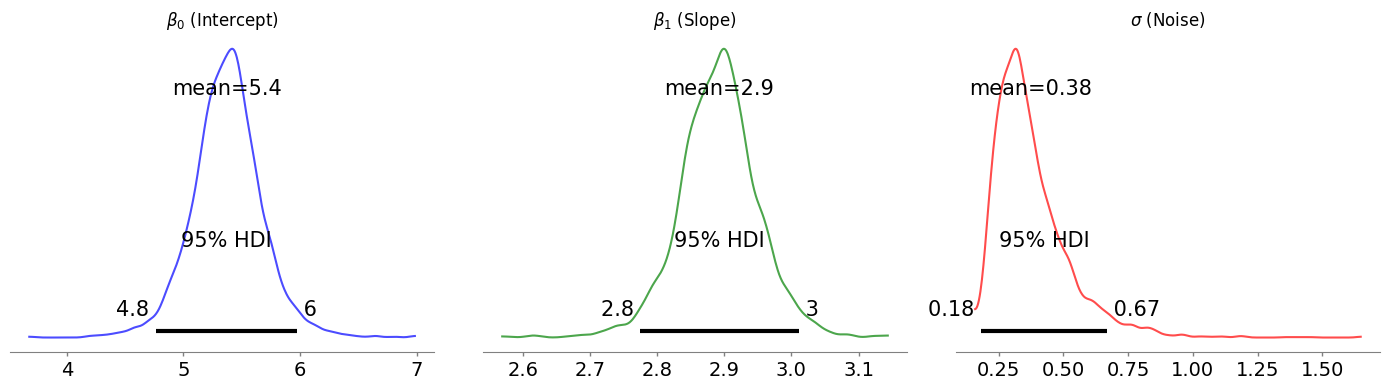

In [7]:
# Plot posterior distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

var_names = ['beta_0', 'beta_1', 'sigma']
titles = [r'$\beta_0$ (Intercept)', r'$\beta_1$ (Slope)', r'$\sigma$ (Noise)']
colors = ['blue', 'green', 'red']

for i, (var, title, color) in enumerate(zip(var_names, titles, colors)):
    az.plot_posterior(trace, var_names=[var], ax=axes[i], 
                      hdi_prob=0.95, color=color, alpha=0.7)
    axes[i].set_title(title, fontsize=12)

plt.tight_layout()
plt.show()

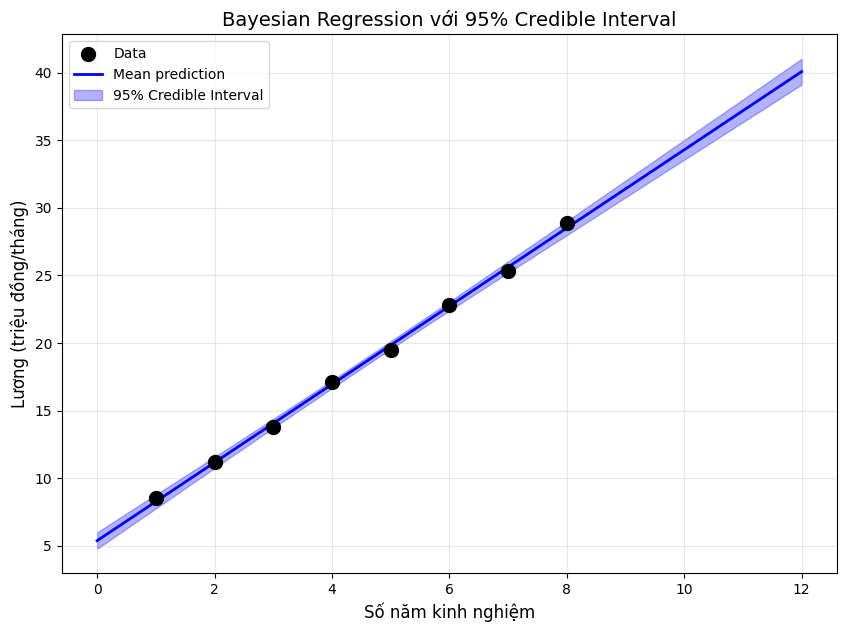

In [8]:
# Plot regression line with 95% credible interval
fig, ax = plt.subplots(figsize=(10, 7))

# Get posterior samples
beta_0_samples = trace.posterior['beta_0'].values.flatten()
beta_1_samples = trace.posterior['beta_1'].values.flatten()

# Create new x values for prediction
x_new = np.linspace(0, 12, 100)

# Calculate predicted y for each posterior sample
y_pred = beta_0_samples[:, np.newaxis] + beta_1_samples[:, np.newaxis] * x_new

# Calculate mean and 95% credible interval
y_mean = np.mean(y_pred, axis=0)
y_lower = np.percentile(y_pred, 2.5, axis=0)
y_upper = np.percentile(y_pred, 97.5, axis=0)

# Plot
ax.scatter(x, y, color='black', s=100, zorder=5, label='Data')
ax.plot(x_new, y_mean, 'b-', linewidth=2, label='Mean prediction')
ax.fill_between(x_new, y_lower, y_upper, alpha=0.3, color='blue', label='95% Credible Interval')

ax.set_xlabel('Số năm kinh nghiệm', fontsize=12)
ax.set_ylabel('Lương (triệu đồng/tháng)', fontsize=12)
ax.set_title('Bayesian Regression với 95% Credible Interval', fontsize=14)
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

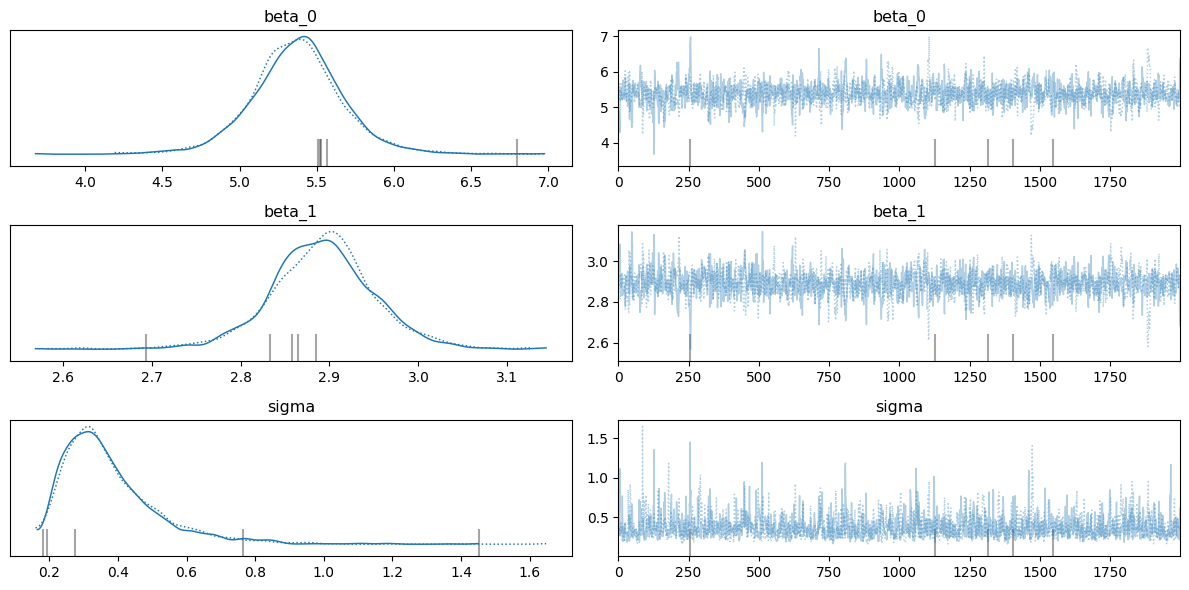

In [9]:
# Trace plots
az.plot_trace(trace, var_names=['beta_0', 'beta_1', 'sigma'])
plt.tight_layout()
plt.show()

**b) Đọc kết quả và kiểm tra hội tụ**

**Trace plots:** Mỗi tham số cần có:
- *Rank plots* hoặc *trace* trông như 'caterpillar' (sâu bướm) — không có xu hướng, không bị kẹt ở một vùng.
- $\hat{R} \approx 1.0$ (< 1.01): các chain đã hội tụ về cùng phân phối.
- $\text{ESS} > 400$: số mẫu hiệu quả đủ lớn.

**Posterior distributions:**
- $\beta_0$: intercept — mức lương khi kinh nghiệm = 0 (ngoại suy, cần thận trọng).
- $\beta_1$: slope — mỗi năm kinh nghiệm tăng thêm bao nhiêu triệu đồng. Đây là tham số quan trọng nhất.
- $\sigma$: độ lệch chuẩn của noise — đo mức độ phân tán của lương thực tế quanh đường hồi quy.

**95% Credible Interval** (HDI) của $\beta_1$: nếu khoảng này không chứa 0, có bằng chứng mạnh rằng kinh nghiệm có ảnh hưởng dương đến lương.

In [10]:
# Prediction for x = 10 years
x_pred = 10

y_pred_10 = beta_0_samples + beta_1_samples * x_pred

print("=== DỰ BÁO LƯƠNG CHO 10 NĂM KINH NGHIỆM ===\n")
print(f"Mean: {np.mean(y_pred_10):.2f} triệu đồng/tháng")
print(f"Median: {np.median(y_pred_10):.2f} triệu đồng/tháng")
print(f"Std: {np.std(y_pred_10):.2f} triệu đồng/tháng")
print(f"95% Credible Interval: [{np.percentile(y_pred_10, 2.5):.2f}, {np.percentile(y_pred_10, 97.5):.2f}]")

=== DỰ BÁO LƯƠNG CHO 10 NĂM KINH NGHIỆM ===

Mean: 34.29 triệu đồng/tháng
Median: 34.29 triệu đồng/tháng
Std: 0.36 triệu đồng/tháng
95% Credible Interval: [33.56, 35.01]


**c) Diễn giải kết quả dự báo**

Kết quả dự báo lương cho nhân viên **10 năm kinh nghiệm** bao gồm:

- **Mean/Median**: ước lượng điểm tốt nhất (posterior mean ≈ posterior median vì phân phối gần đối xứng).
- **Std**: độ bất định của dự báo — phản ánh cả uncertainty về tham số (parameter uncertainty) lẫn noise tự nhiên của dữ liệu.
- **95% Credible Interval**: khoảng $[L, U]$ có nghĩa là "với 95% xác suất, lương thực tế của nhân viên 10 năm kinh nghiệm nằm trong $[L, U]$ triệu đồng".

**Lưu ý về ngoại suy (extrapolation):**
Dữ liệu huấn luyện chỉ có $x \in [1, 8]$. Dự báo tại $x=10$ là **ngoại suy** — mô hình giả định quan hệ tuyến tính vẫn giữ nguyên ngoài vùng dữ liệu. Credible interval sẽ rộng hơn so với nội suy, phản ánh bất định tăng lên.

In [11]:
# Interpretation
print("\n=== Ý NGHĨA CỦA KẾT QUẢ ===\n")
print(f"β₀ (Intercept): {np.mean(beta_0_samples):.2f} ± {np.std(beta_0_samples):.2f}")
print(f"β₁ (Slope): {np.mean(beta_1_samples):.2f} ± {np.std(beta_1_samples):.2f}")
print(f"σ (Noise): {np.mean(trace.posterior['sigma'].values):.2f} ± {np.std(trace.posterior['sigma'].values):.2f}")

print("\nGiải thích:")
print(f"- Mỗi năm kinh nghiệm tăng, lương tăng trung bình {np.mean(beta_1_samples):.2f} triệu đồng")
print(f"- Với 95% tin cậy, mỗi năm kinh nghiệm tăng lương từ {np.percentile(beta_1_samples, 2.5):.2f} đến {np.percentile(beta_1_samples, 97.5):.2f} triệu")
print(f"- Dự báo lương cho 10 năm kinh nghiệm: {np.mean(y_pred_10):.2f} triệu (95% CI: [{np.percentile(y_pred_10, 2.5):.2f}, {np.percentile(y_pred_10, 97.5):.2f}])")


=== Ý NGHĨA CỦA KẾT QUẢ ===

β₀ (Intercept): 5.37 ± 0.30
β₁ (Slope): 2.89 ± 0.06
σ (Noise): 0.38 ± 0.14

Giải thích:
- Mỗi năm kinh nghiệm tăng, lương tăng trung bình 2.89 triệu đồng
- Với 95% tin cậy, mỗi năm kinh nghiệm tăng lương từ 2.77 đến 3.01 triệu
- Dự báo lương cho 10 năm kinh nghiệm: 34.29 triệu (95% CI: [33.56, 35.01])


---

## --------------------------------------- Hết --------------------------------------

**Đáp án được tổng hợp bởi:** Giảng viên
**Ngày:** __/__/2026